## FIFA 20 Player Analytics: Data Analysis, Clustering & Machine Learning

- **Project Code:** PRCP-1004-Fifa20 | **Domain:** Sports | **Dataset:** FIFA 20 Career Mode player data (players_20.csv)
- **Author:** Data Science Capstone Project
- **Objective:** Perform a complete data analysis on FIFA 20 player attributes, cluster players by skillset, answer the three specified analytical questions, and build/compare machine learning models.


### Python Environment Verification

In [1]:
import sys
print("Python version:", sys.version)


Python version: 3.12.3 (main, Mar  3 2026, 12:15:18) [GCC 13.3.0]


### Library and Version Verification

In [2]:
import pandas as pd
import numpy as np
import matplotlib
import seaborn as sns
import sklearn
import matplotlib.pyplot as plt

print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("matplotlib:", matplotlib.__version__)
print("seaborn:", sns.__version__)
print("scikit-learn:", sklearn.__version__)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
pd.set_option("display.max_columns", 60)


pandas: 3.0.2
numpy: 2.4.4
matplotlib: 3.10.8
seaborn: 0.13.2
scikit-learn: 1.8.0


## 1. Data Loading and Understanding

### Loading the FIFA 20 Dataset

In [3]:
df = pd.read_csv("../data/players_20.csv")
print("Dataset loaded successfully.")
print("Shape (rows, columns):", df.shape)


Dataset loaded successfully.
Shape (rows, columns): (18278, 104)


### Initial Dataset Inspection

In [4]:
df.head()


,sofifa_id,player_url,short_name,long_name,age,dob,height_cm,weight_kg,nationality,club,overall,potential,value_eur,wage_eur,player_positions,preferred_foot,international_reputation,weak_foot,skill_moves,work_rate,body_type,real_face,release_clause_eur,player_tags,team_position,team_jersey_number,loaned_from,joined,contract_valid_until,nation_position,...,goalkeeping_handling,goalkeeping_kicking,goalkeeping_positioning,goalkeeping_reflexes,ls,st,rs,lw,lf,cf,rf,rw,lam,cam,ram,lm,lcm,cm,rcm,rm,lwb,ldm,cdm,rdm,rwb,lb,lcb,cb,rcb,rb
0,158023,https://sofifa.com/player/158023/lionel-messi/...,L. Messi,Lionel Andrés Messi Cuccittini,32,1987-06-24,170,72,Argentina,FC Barcelona,94,94,95500000,565000,"RW, CF, ST",Left,5,4,4,Medium/Low,Messi,Yes,195800000.0,"#Dribbler, #Distance Shooter, #Crosser, #FK Sp...",RW,10.0,NaN,2004-07-01,2021.0,NaN,...,11,15,14,8,89+2,89+2,89+2,93+2,93+2,93+2,93+2,93+2,93+2,93+2,93+2,92+2,87+2,87+2,87+2,92+2,68+2,66+2,66+2,66+2,68+2,63+2,52+2,52+2,52+2,63+2
1,20801,https://sofifa.com/player/20801/c-ronaldo-dos-...,Cristiano Ronaldo,Cristiano Ronaldo dos Santos Aveiro,34,1985-02-05,187,83,Portugal,Juventus,93,93,58500000,405000,"ST, LW",Right,5,4,5,High/Low,C. Ronaldo,Yes,96500000.0,"#Speedster, #Dribbler, #Distance Shooter, #Acr...",LW,7.0,NaN,2018-07-10,2022.0,LS,...,11,15,14,11,91+3,91+3,91+3,89+3,90+3,90+3,90+3,89+3,88+3,88+3,88+3,88+3,81+3,81+3,81+3,88+3,65+3,61+3,61+3,61+3,65+3,61+3,53+3,53+3,53+3,61+3
2,190871,https://sofifa.com/player/190871/neymar-da-sil...,Neymar Jr,Neymar da Silva Santos Junior,27,1992-02-05,175,68,Brazil,Paris Saint-Germain,92,92,105500000,290000,"LW, CAM",Right,5,5,5,High/Medium,Neymar,Yes,195200000.0,"#Speedster, #Dribbler, #Playmaker , #Crosser,...",CAM,10.0,NaN,2017-08-03,2022.0,LW,...,9,15,15,11,84+3,84+3,84+3,90+3,89+3,89+3,89+3,90+3,90+3,90+3,90+3,89+3,82+3,82+3,82+3,89+3,66+3,61+3,61+3,61+3,66+3,61+3,46+3,46+3,46+3,61+3
3,200389,https://sofifa.com/player/200389/jan-oblak/20/...,J. Oblak,Jan Oblak,26,1993-01-07,188,87,Slovenia,Atlético Madrid,91,93,77500000,125000,GK,Right,3,3,1,Medium/Medium,Normal,Yes,164700000.0,NaN,GK,13.0,NaN,2014-07-16,2023.0,GK,...,92,78,90,89,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,183277,https://sofifa.com/player/183277/eden-hazard/2...,E. Hazard,Eden Hazard,28,1991-01-07,175,74,Belgium,Real Madrid,91,91,90000000,470000,"LW, CF",Right,4,4,4,High/Medium,Normal,Yes,184500000.0,"#Speedster, #Dribbler, #Acrobat",LW,7.0,NaN,2019-07-01,2024.0,LF,...,12,6,8,8,83+3,83+3,83+3,89+3,88+3,88+3,88+3,89+3,89+3,89+3,89+3,89+3,83+3,83+3,83+3,89+3,66+3,63+3,63+3,63+3,66+3,61+3,49+3,49+3,49+3,61+3


In [5]:
df.tail(3)


,sofifa_id,player_url,short_name,long_name,age,dob,height_cm,weight_kg,nationality,club,overall,potential,value_eur,wage_eur,player_positions,preferred_foot,international_reputation,weak_foot,skill_moves,work_rate,body_type,real_face,release_clause_eur,player_tags,team_position,team_jersey_number,loaned_from,joined,contract_valid_until,nation_position,...,goalkeeping_handling,goalkeeping_kicking,goalkeeping_positioning,goalkeeping_reflexes,ls,st,rs,lw,lf,cf,rf,rw,lam,cam,ram,lm,lcm,cm,rcm,rm,lwb,ldm,cdm,rdm,rwb,lb,lcb,cb,rcb,rb
18275,252332,https://sofifa.com/player/252332/wei-zhang/20/...,Zhang Wei,张威,19,2000-05-16,186,75,China PR,Hebei China Fortune FC,48,56,40000,1000,CM,Right,1,2,2,Low/Medium,Lean,No,70000.0,NaN,SUB,38.0,NaN,2019-01-01,2019.0,NaN,...,8,10,6,14,43+2,43+2,43+2,43+2,43+2,43+2,43+2,43+2,44+2,44+2,44+2,45+2,46+2,46+2,46+2,45+2,47+2,49+2,49+2,49+2,47+2,47+2,49+2,49+2,49+2,47+2
18276,251110,https://sofifa.com/player/251110/haijian-wang/...,Wang Haijian,汪海健,18,2000-08-02,185,74,China PR,Shanghai Greenland Shenhua FC,48,54,40000,1000,CM,Right,1,2,2,Low/Low,Lean,No,70000.0,NaN,SUB,33.0,NaN,2019-02-01,2022.0,NaN,...,9,13,13,13,43+2,43+2,43+2,45+2,44+2,44+2,44+2,45+2,46+2,46+2,46+2,46+2,46+2,46+2,46+2,46+2,48+2,48+2,48+2,48+2,48+2,48+2,49+2,49+2,49+2,48+2
18277,233449,https://sofifa.com/player/233449/ximing-pan/20...,Pan Ximing,潘喜明,26,1993-01-11,182,78,China PR,Hebei China Fortune FC,48,51,40000,2000,CM,Right,1,3,2,Medium/Medium,Normal,No,NaN,NaN,SUB,37.0,Tianjin TEDA FC,NaN,2019.0,NaN,...,12,14,9,10,42+2,42+2,42+2,44+2,43+2,43+2,43+2,44+2,46+2,46+2,46+2,46+2,46+2,46+2,46+2,46+2,48+2,49+2,49+2,49+2,48+2,48+2,50+2,50+2,50+2,48+2


In [6]:
df.info(verbose=False)


<class 'pandas.DataFrame'>
RangeIndex: 18278 entries, 0 to 18277
Columns: 104 entries, sofifa_id to rb
dtypes: float64(16), int64(45), str(43)
memory usage: 14.5 MB


### Column Names and Data Types

In [7]:
dtype_summary = df.dtypes.value_counts()
print(dtype_summary)
print()
print("Total columns:", df.shape[1])


int64      45
str        43
float64    16
Name: count, dtype: int64

Total columns: 104


### Descriptive Statistics (Numeric Columns)

In [8]:
df[['age','height_cm','weight_kg','overall','potential','value_eur','wage_eur']].describe().T


,count,mean,std,min,25%,50%,75%,max
age,18278.0,2.528329e+01,4.656964e+00,16.0,22.0,25.0,29.0,42.0
height_cm,18278.0,1.813622e+02,6.756961e+00,156.0,177.0,181.0,186.0,205.0
weight_kg,18278.0,7.527634e+01,7.047744e+00,50.0,70.0,75.0,80.0,110.0
overall,18278.0,6.624499e+01,6.949953e+00,48.0,62.0,66.0,71.0,94.0
potential,18278.0,7.154689e+01,6.139669e+00,49.0,67.0,71.0,75.0,95.0
value_eur,18278.0,2.484038e+06,5.585481e+06,0.0,325000.0,700000.0,2100000.0,105500000.0
wage_eur,18278.0,9.456943e+03,2.135171e+04,0.0,1000.0,3000.0,8000.0,565000.0


### Duplicate Records Check

In [9]:
print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicate sofifa_id (unique player key):", df['sofifa_id'].duplicated().sum())


Fully duplicated rows: 0
Duplicate sofifa_id (unique player key): 0


### Missing Value Summary

In [10]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(1)
missing_summary = pd.DataFrame({'missing_count': missing, 'missing_pct': missing_pct})
missing_summary.head(25)


,missing_count,missing_pct
loaned_from,17230,94.3
nation_position,17152,93.8
nation_jersey_number,17152,93.8
player_tags,16779,91.8
gk_diving,16242,88.9
gk_reflexes,16242,88.9
gk_kicking,16242,88.9
gk_handling,16242,88.9
gk_speed,16242,88.9
gk_positioning,16242,88.9


## 2. Data Preprocessing

### Confirming the Goalkeeper / Outfield Missing-Value Pattern

In [11]:
outfield_stat_cols = ['pace','shooting','passing','dribbling','defending','physic']
gk_stat_cols = ['gk_diving','gk_handling','gk_kicking','gk_reflexes','gk_speed','gk_positioning']

is_gk = df['player_positions'].str.split(',').str[0].str.strip() == 'GK'
print("Number of goalkeepers:", is_gk.sum())
print()
print("Missing outfield-attribute values among goalkeepers:")
print(df.loc[is_gk, outfield_stat_cols].isnull().sum())
print()
print("Missing goalkeeper-attribute values among outfield players:")
print(df.loc[~is_gk, gk_stat_cols].isnull().sum())


Number of goalkeepers: 2036

Missing outfield-attribute values among goalkeepers:
pace         2036
shooting     2036
passing      2036
dribbling    2036
defending    2036
physic       2036
dtype: int64

Missing goalkeeper-attribute values among outfield players:
gk_diving         16242
gk_handling       16242
gk_kicking        16242
gk_reflexes       16242
gk_speed          16242
gk_positioning    16242
dtype: int64


### Handling Remaining Missing / Low-Value Columns

In [ ]:
drop_cols = ['loaned_from', 'nation_position', 'nation_jersey_number', 'player_tags',
             'player_traits', 'real_face', 'body_type', 'team_jersey_number']

position_rating_cols = ['ls','st','rs','lw','lf','cf','rf','rw','lam','cam','ram','lm',
                         'lcm','cm','rcm','rm','lwb','ldm','cdm','rdm','rwb','lb','lcb',
                         'cb','rcb','rb']
drop_cols += position_rating_cols

df_clean = df.drop(columns=[c for c in drop_cols if c in df.columns]).copy()
print("Columns dropped:", len(drop_cols))
print("Remaining shape:", df_clean.shape)


Columns dropped: 34
Remaining shape: (18278, 70)


### Data Type Conversion

In [13]:
df_clean['dob'] = pd.to_datetime(df_clean['dob'], errors='coerce')
df_clean['joined'] = pd.to_datetime(df_clean['joined'], errors='coerce')

for col in ['nationality', 'club', 'preferred_foot', 'work_rate']:
    df_clean[col] = df_clean[col].astype('category')

print(df_clean[['dob','joined']].dtypes)
print(df_clean[['nationality','club','preferred_foot','work_rate']].dtypes)


dob       datetime64[us]
joined    datetime64[us]
dtype: object
nationality       category
club              category
preferred_foot    category
work_rate         category
dtype: object


### Text Cleaning

In [14]:
for col in ['short_name', 'long_name', 'club', 'nationality']:
    df_clean[col] = df_clean[col].astype(str).str.strip()

print("Sample cleaned names:")
df_clean[['short_name','long_name','club','nationality']].head(3)


Sample cleaned names:


,short_name,long_name,club,nationality
0,L. Messi,Lionel Andrés Messi Cuccittini,FC Barcelona,Argentina
1,Cristiano Ronaldo,Cristiano Ronaldo dos Santos Aveiro,Juventus,Portugal
2,Neymar Jr,Neymar da Silva Santos Junior,Paris Saint-Germain,Brazil


### Feature Preparation: Position Grouping

In [ ]:
df_clean['primary_position'] = df_clean['player_positions'].str.split(',').str[0].str.strip()

position_group_map = {
    'GK': 'GK',
    'CB': 'DEF', 'LB': 'DEF', 'RB': 'DEF', 'LWB': 'DEF', 'RWB': 'DEF',
    'CDM': 'MID', 'CM': 'MID', 'CAM': 'MID', 'LM': 'MID', 'RM': 'MID',
    'ST': 'FWD', 'CF': 'FWD', 'LW': 'FWD', 'RW': 'FWD', 'LF': 'FWD', 'RF': 'FWD',
    'LS': 'FWD', 'RS': 'FWD'
}
df_clean['position_group'] = df_clean['primary_position'].map(position_group_map)

print(df_clean['primary_position'].value_counts())
print()
print(df_clean['position_group'].value_counts())


primary_position
CB     3162
ST     2582
CM     2193
GK     2036
CDM    1424
RB     1314
LB     1303
CAM    1146
RM     1050
LM     1049
LW      378
RW      369
CF      113
LWB      90
RWB      69
Name: count, dtype: int64

position_group
MID    6862
DEF    5938
FWD    3442
GK     2036
Name: count, dtype: int64


### Feature Preparation: Work Rate Split

In [ ]:
work_rate_map = {'Low': 0, 'Medium': 0.5, 'High': 1}

wr_split = df_clean['work_rate'].astype(str).str.split('/', expand=True)
df_clean['attack_work_rate'] = wr_split[0].map(work_rate_map)
df_clean['defense_work_rate'] = wr_split[1].map(work_rate_map)

df_clean[['work_rate','attack_work_rate','defense_work_rate']].drop_duplicates().sort_values('work_rate')


,work_rate,attack_work_rate,defense_work_rate
5,High/High,1.0,1.0
1,High/Low,1.0,0.0
2,High/Medium,1.0,0.5
67,Low/High,0.0,1.0
5865,Low/Low,0.0,0.0
136,Low/Medium,0.0,0.5
11,Medium/High,0.5,1.0
0,Medium/Low,0.5,0.0
3,Medium/Medium,0.5,0.5


### Feature Preparation: Preferred Foot Encoding

In [17]:
df_clean['preferred_foot_encoded'] = (df_clean['preferred_foot'] == 'Right').astype(int)
print(df_clean[['preferred_foot','preferred_foot_encoded']].drop_duplicates())


  preferred_foot  preferred_foot_encoded
0           Left                       0
1          Right                       1


### Final Preprocessed Dataset Snapshot

In [18]:
print("Final preprocessed shape:", df_clean.shape)
df_clean[['short_name','age','nationality','club','overall','potential','value_eur',
          'wage_eur','primary_position','position_group']].head()


Final preprocessed shape: (18278, 75)


,short_name,age,nationality,club,overall,potential,value_eur,wage_eur,primary_position,position_group
0,L. Messi,32,Argentina,FC Barcelona,94,94,95500000,565000,RW,FWD
1,Cristiano Ronaldo,34,Portugal,Juventus,93,93,58500000,405000,ST,FWD
2,Neymar Jr,27,Brazil,Paris Saint-Germain,92,92,105500000,290000,LW,FWD
3,J. Oblak,26,Slovenia,Atlético Madrid,91,93,77500000,125000,GK,GK
4,E. Hazard,28,Belgium,Real Madrid,91,91,90000000,470000,LW,FWD


## 3. Exploratory Data Analysis

### Univariate Analysis: Age, Overall, Potential

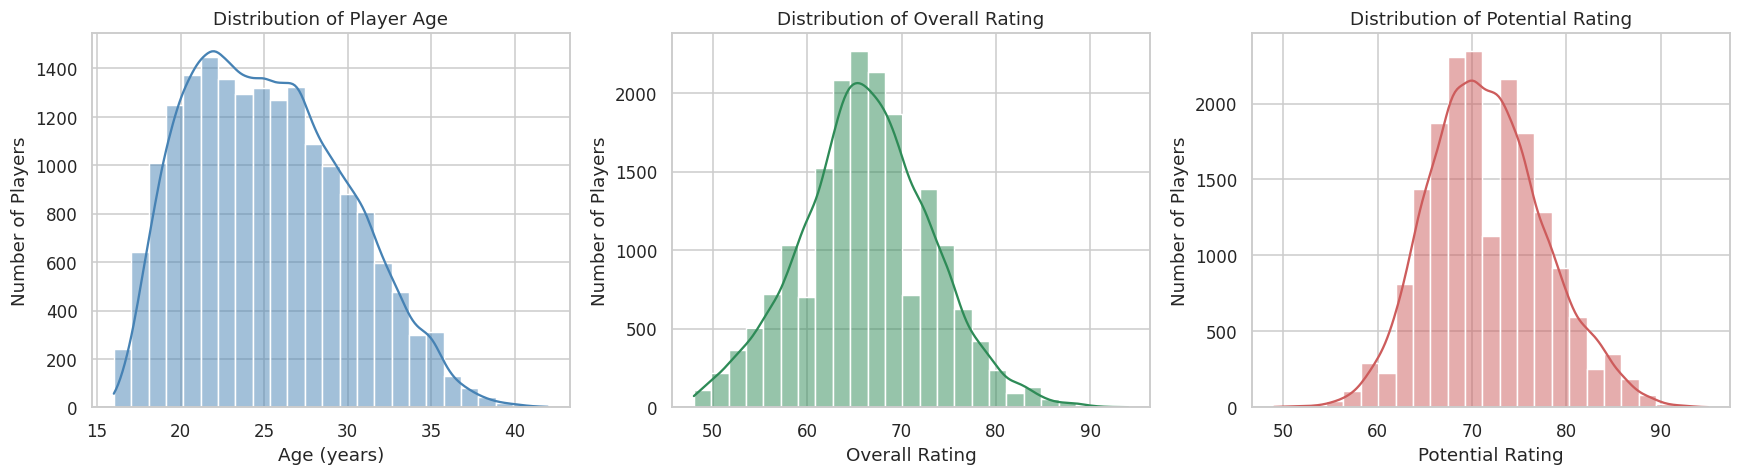

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.histplot(df_clean['age'], bins=25, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Distribution of Player Age')
axes[0].set_xlabel('Age (years)'); axes[0].set_ylabel('Number of Players')

sns.histplot(df_clean['overall'], bins=25, kde=True, ax=axes[1], color='seagreen')
axes[1].set_title('Distribution of Overall Rating')
axes[1].set_xlabel('Overall Rating'); axes[1].set_ylabel('Number of Players')

sns.histplot(df_clean['potential'], bins=25, kde=True, ax=axes[2], color='indianred')
axes[2].set_title('Distribution of Potential Rating')
axes[2].set_xlabel('Potential Rating'); axes[2].set_ylabel('Number of Players')

plt.tight_layout()
plt.show()


### Univariate Analysis: Market Value and Wage

Value (EUR) skewness: 6.43
Wage (EUR) skewness: 7.82


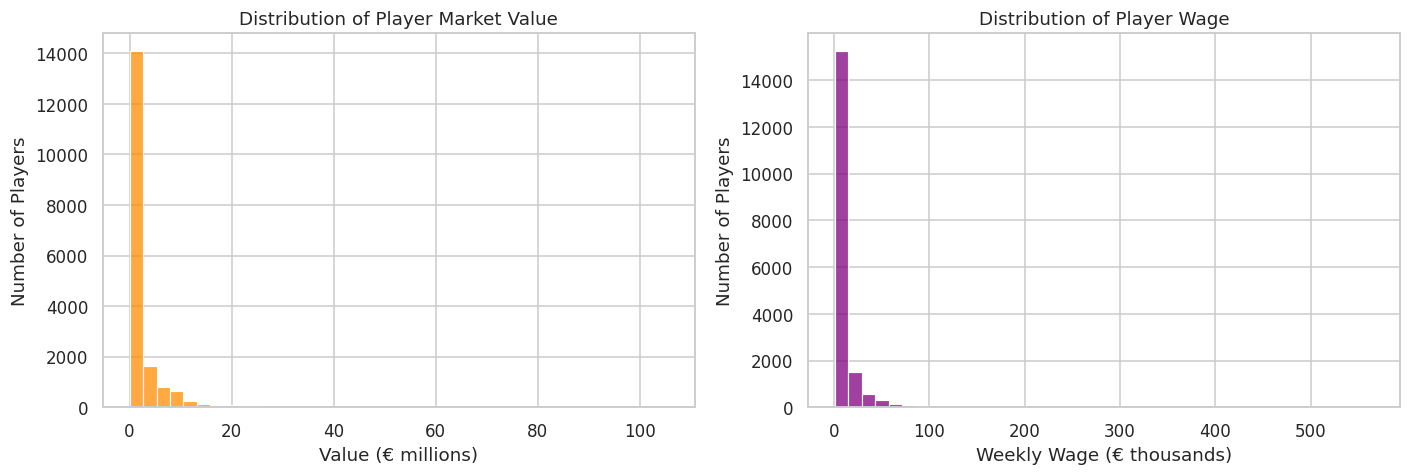

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df_clean.loc[df_clean['value_eur'] > 0, 'value_eur'] / 1e6, bins=40, ax=axes[0], color='darkorange')
axes[0].set_title('Distribution of Player Market Value')
axes[0].set_xlabel('Value (€ millions)'); axes[0].set_ylabel('Number of Players')

sns.histplot(df_clean.loc[df_clean['wage_eur'] > 0, 'wage_eur'] / 1000, bins=40, ax=axes[1], color='purple')
axes[1].set_title('Distribution of Player Wage')
axes[1].set_xlabel('Weekly Wage (€ thousands)'); axes[1].set_ylabel('Number of Players')

plt.tight_layout()
plt.show()

print("Value (EUR) skewness:", round(df_clean['value_eur'].skew(), 2))
print("Wage (EUR) skewness:", round(df_clean['wage_eur'].skew(), 2))


### Boxplots: Overall Rating and Value by Position Group

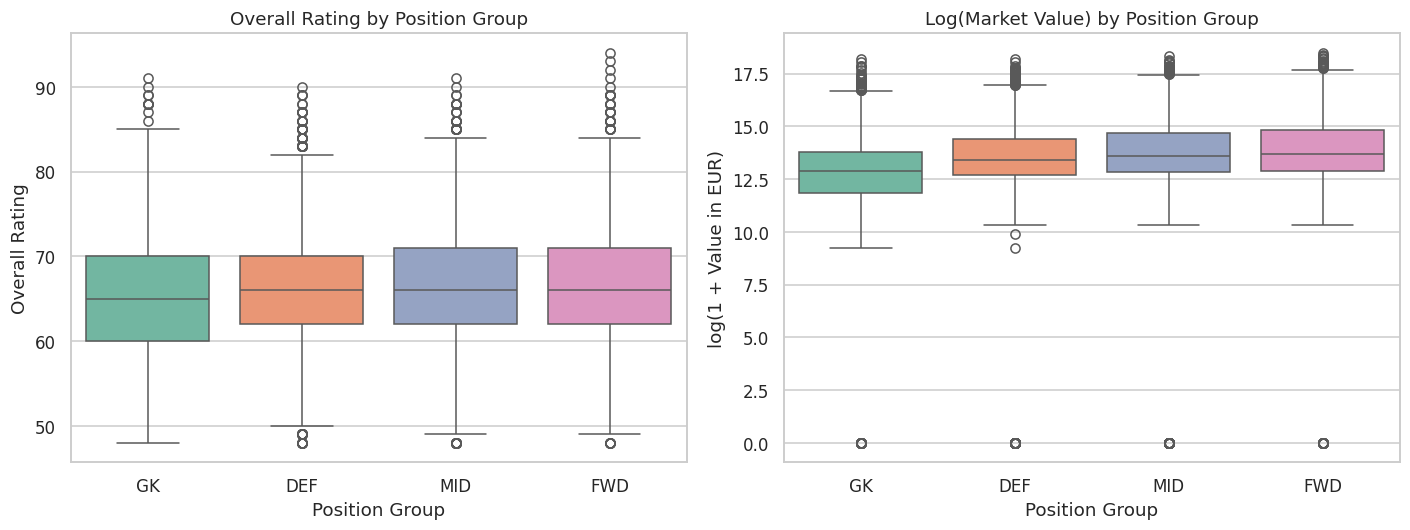

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
order = ['GK', 'DEF', 'MID', 'FWD']
sns.boxplot(data=df_clean, x='position_group', y='overall', order=order, ax=axes[0], palette='Set2')
axes[0].set_title('Overall Rating by Position Group')
axes[0].set_xlabel('Position Group'); axes[0].set_ylabel('Overall Rating')

sns.boxplot(data=df_clean, x='position_group', y=np.log1p(df_clean['value_eur']), order=order, ax=axes[1], palette='Set2')
axes[1].set_title('Log(Market Value) by Position Group')
axes[1].set_xlabel('Position Group'); axes[1].set_ylabel('log(1 + Value in EUR)')

plt.tight_layout()
plt.show()


### Bivariate Analysis: Overall vs Potential

Correlation (Overall, Potential): 0.647


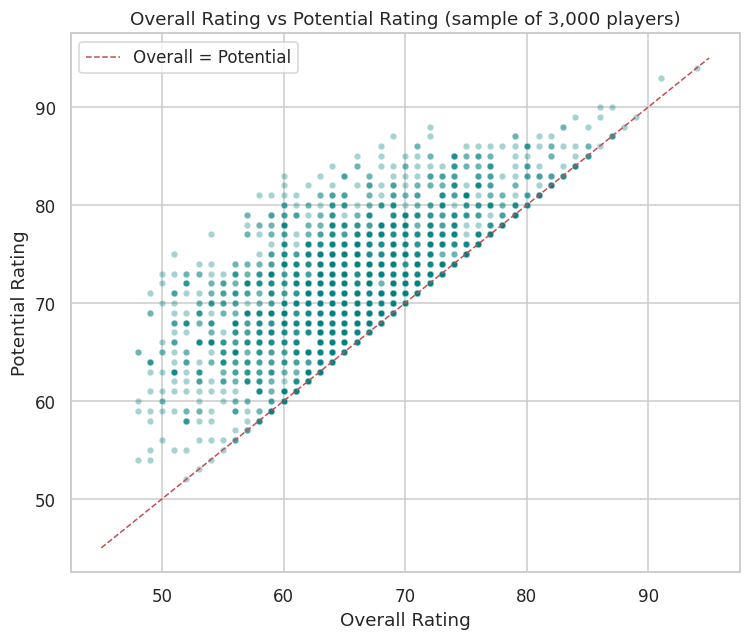

In [22]:
plt.figure(figsize=(7,6))
sns.scatterplot(data=df_clean.sample(3000, random_state=42), x='overall', y='potential',
                 alpha=0.35, s=18, color='teal')
plt.plot([45,95],[45,95],'r--', linewidth=1, label='Overall = Potential')
plt.title('Overall Rating vs Potential Rating (sample of 3,000 players)')
plt.xlabel('Overall Rating'); plt.ylabel('Potential Rating')
plt.legend()
plt.tight_layout()
plt.show()

corr_op = df_clean['overall'].corr(df_clean['potential'])
print("Correlation (Overall, Potential):", round(corr_op, 3))


### Bivariate Analysis: Value & Wage vs Overall Rating

Correlation (Overall, Value): 0.638
Correlation (Overall, Wage): 0.574


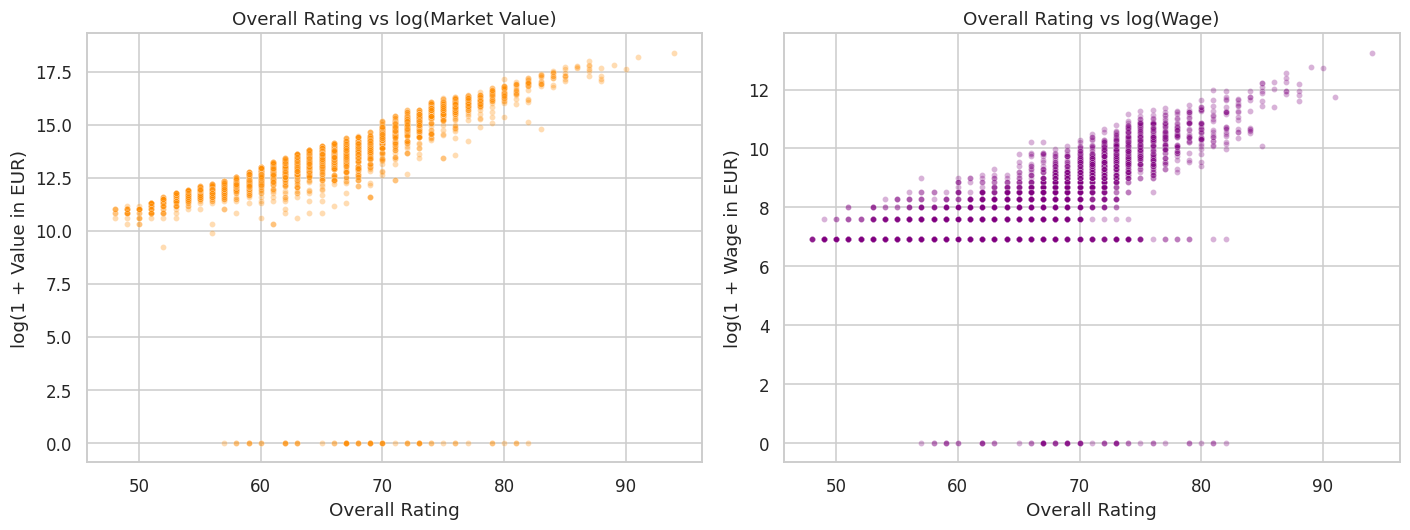

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sample = df_clean.sample(4000, random_state=42)

sns.scatterplot(data=sample, x='overall', y=np.log1p(sample['value_eur']), alpha=0.3, s=15, ax=axes[0], color='darkorange')
axes[0].set_title('Overall Rating vs log(Market Value)')
axes[0].set_xlabel('Overall Rating'); axes[0].set_ylabel('log(1 + Value in EUR)')

sns.scatterplot(data=sample, x='overall', y=np.log1p(sample['wage_eur']), alpha=0.3, s=15, ax=axes[1], color='purple')
axes[1].set_title('Overall Rating vs log(Wage)')
axes[1].set_xlabel('Overall Rating'); axes[1].set_ylabel('log(1 + Wage in EUR)')

plt.tight_layout()
plt.show()

print("Correlation (Overall, Value):", round(df_clean['overall'].corr(df_clean['value_eur']), 3))
print("Correlation (Overall, Wage):", round(df_clean['overall'].corr(df_clean['wage_eur']), 3))


### Categorical Analysis: Preferred Foot, Work Rate, International Reputation

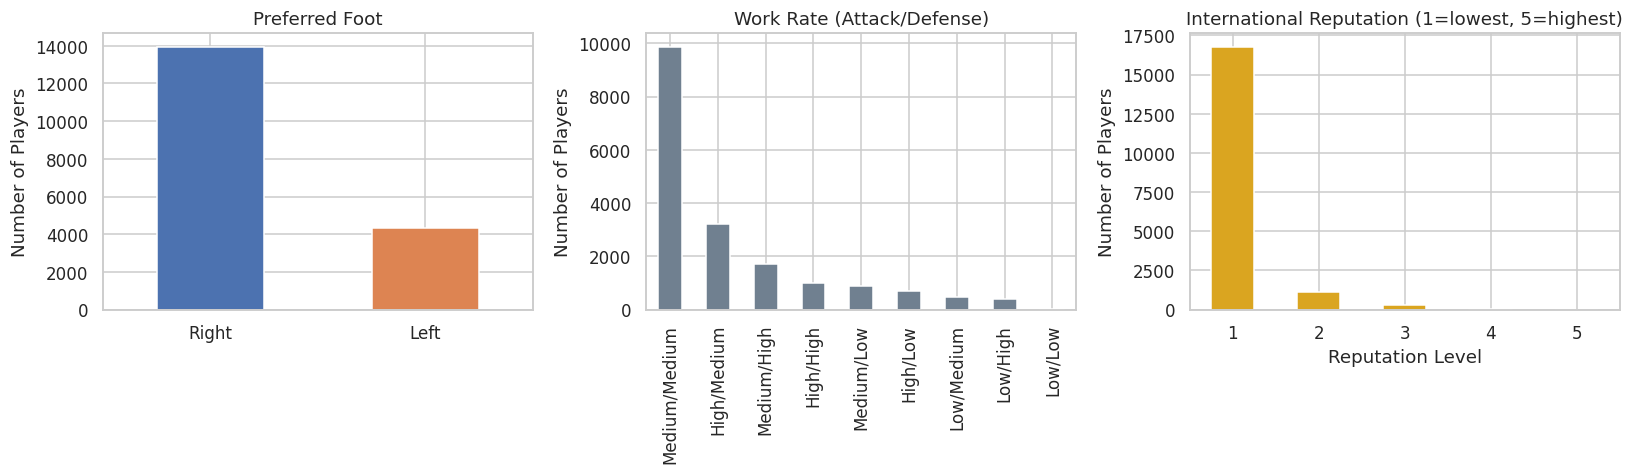

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
df_clean['preferred_foot'].value_counts().plot(kind='bar', ax=axes[0], color=['#4C72B0','#DD8452'])
axes[0].set_title('Preferred Foot'); axes[0].set_xlabel(''); axes[0].set_ylabel('Number of Players')
axes[0].tick_params(axis='x', rotation=0)

df_clean['work_rate'].value_counts().head(9).plot(kind='bar', ax=axes[1], color='slategray')
axes[1].set_title('Work Rate (Attack/Defense)'); axes[1].set_xlabel(''); axes[1].set_ylabel('Number of Players')

df_clean['international_reputation'].value_counts().sort_index().plot(kind='bar', ax=axes[2], color='goldenrod')
axes[2].set_title('International Reputation (1=lowest, 5=highest)'); axes[2].set_xlabel('Reputation Level'); axes[2].set_ylabel('Number of Players')
axes[2].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()


### Correlation Analysis

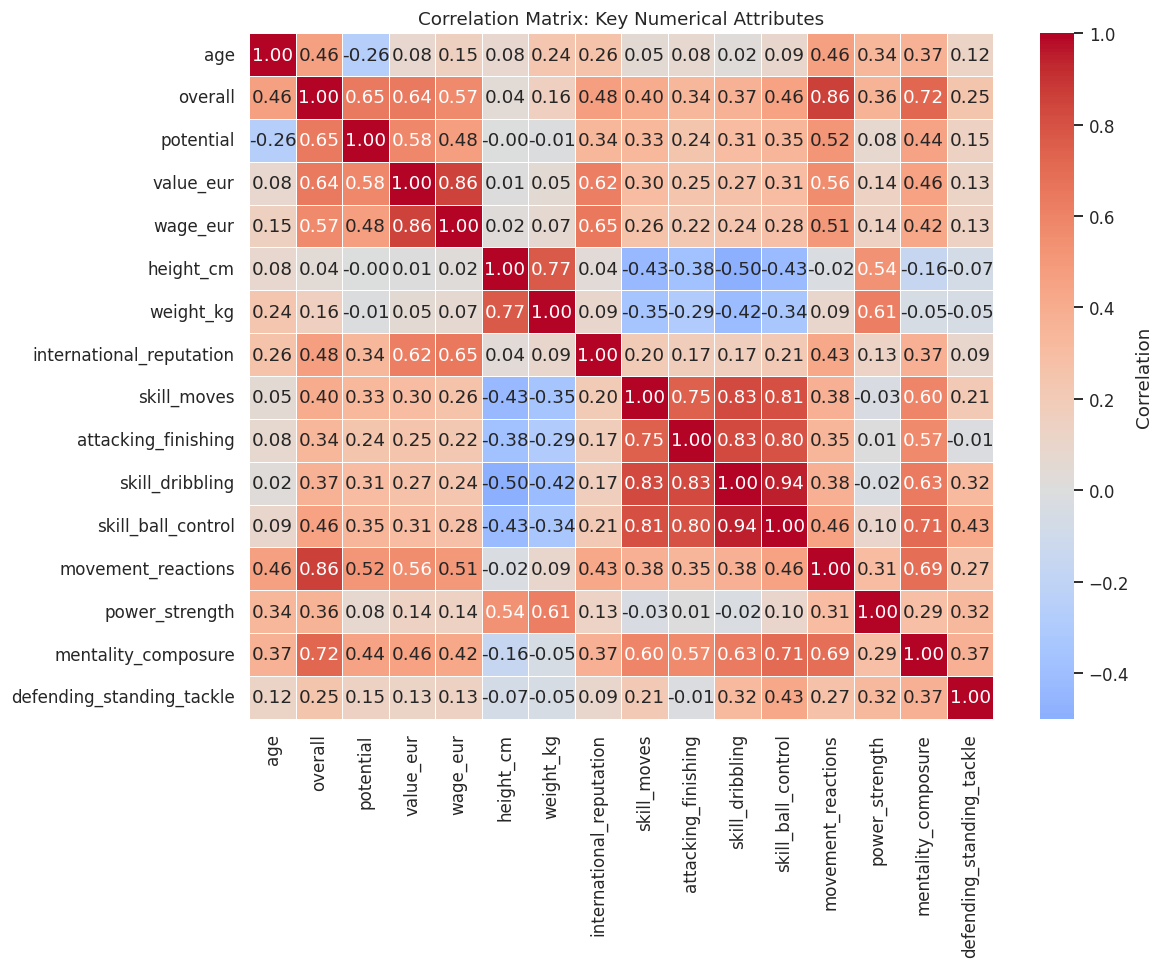

In [25]:
corr_cols = ['age','overall','potential','value_eur','wage_eur','height_cm','weight_kg',
             'international_reputation','skill_moves','attacking_finishing','skill_dribbling',
             'skill_ball_control','movement_reactions','power_strength','mentality_composure',
             'defending_standing_tackle']
corr_matrix = df_clean[corr_cols].corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5,
            cbar_kws={'label': 'Correlation'})
plt.title('Correlation Matrix: Key Numerical Attributes')
plt.tight_layout()
plt.show()


In [26]:
# Report the strongest relationships rather than just the heatmap
corr_pairs = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)).stack()
strongest = corr_pairs.abs().sort_values(ascending=False).head(10)
for (a, b), _ in strongest.items():
    print(f"{a:28s} <-> {b:28s}  r = {corr_matrix.loc[a,b]:+.3f}")


skill_dribbling              <-> skill_ball_control            r = +0.943
overall                      <-> movement_reactions            r = +0.865
value_eur                    <-> wage_eur                      r = +0.858
attacking_finishing          <-> skill_dribbling               r = +0.830
skill_moves                  <-> skill_dribbling               r = +0.828
skill_moves                  <-> skill_ball_control            r = +0.806
attacking_finishing          <-> skill_ball_control            r = +0.796
height_cm                    <-> weight_kg                     r = +0.769
skill_moves                  <-> attacking_finishing           r = +0.748
overall                      <-> mentality_composure           r = +0.720


## Task 3: Answering the Required Analytical Questions

### Question 1 — Top 10 Countries With the Most Players

nationality
England        1667
Germany        1216
Spain          1035
France          984
Argentina       886
Brazil          824
Italy           732
Colombia        591
Japan           453
Netherlands     416
Name: count, dtype: int64


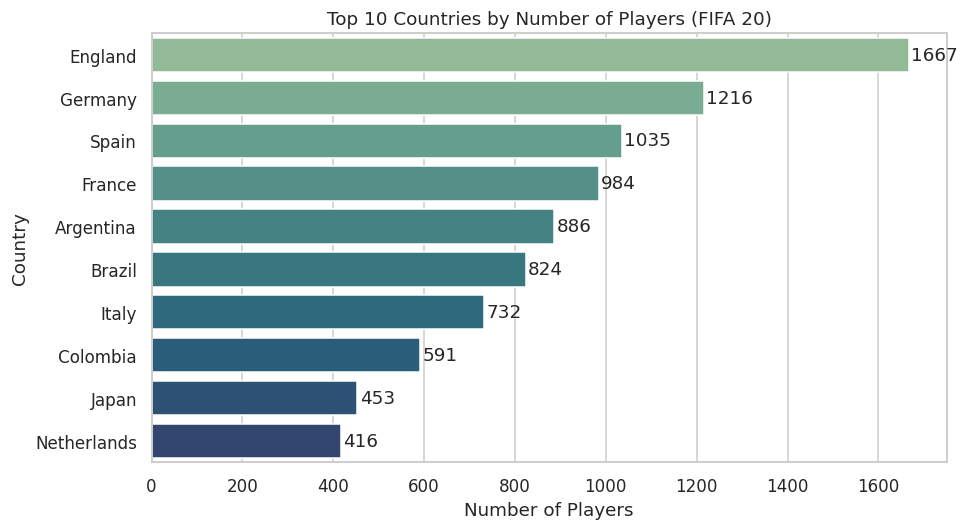

In [27]:
top10_countries = df_clean['nationality'].value_counts().head(10)
print(top10_countries)

plt.figure(figsize=(9,5))
sns.barplot(x=top10_countries.values, y=top10_countries.index, hue=top10_countries.index,
            palette='crest', legend=False)
plt.title('Top 10 Countries by Number of Players (FIFA 20)')
plt.xlabel('Number of Players'); plt.ylabel('Country')
for i, v in enumerate(top10_countries.values):
    plt.text(v + 5, i, str(v), va='center')
plt.tight_layout()
plt.show()


### Question 2 — Overall Rating vs Age: When Do Players Stop Improving?

      mean  count
age              
17   55.79    229
18   57.27    640
19   59.51   1011
20   61.22   1247
21   63.26   1375
22   64.61   1446
23   66.04   1358
24   66.98   1296
25   67.90   1319
26   68.40   1270
27   69.01   1324
28   69.22   1086
29   69.31    999
30   69.42    883
31   69.94    807
32   69.94    597
33   69.49    475
34   69.59    301
35   69.96    310
36   68.15    131
37   67.81     81
38   69.45     42


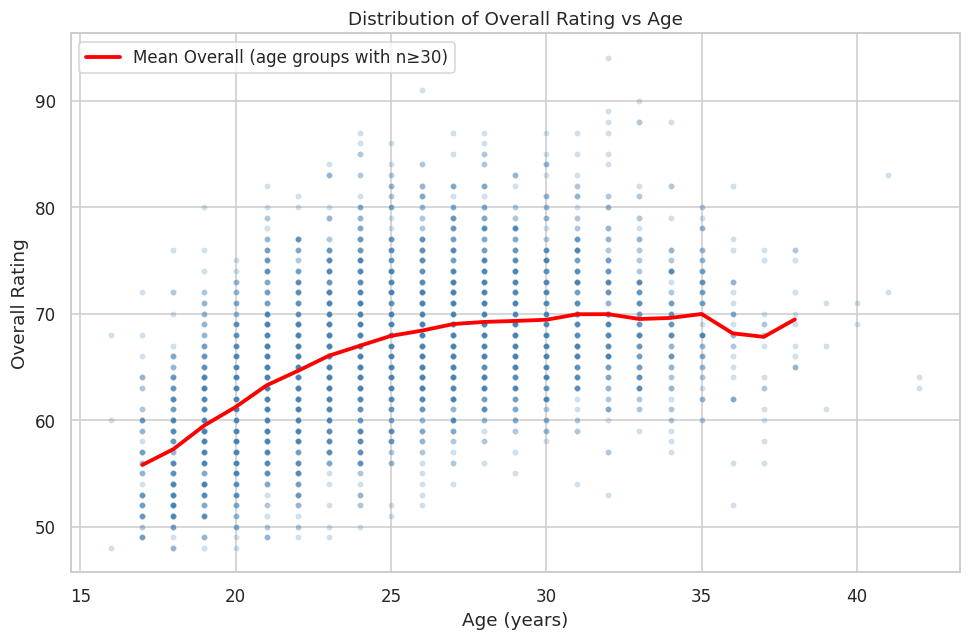

In [28]:
plt.figure(figsize=(9,6))
sns.scatterplot(data=df_clean.sample(4000, random_state=42), x='age', y='overall', alpha=0.25, s=15, color='steelblue')

age_overall = df_clean.groupby('age')['overall'].agg(['mean','count'])
reliable_ages = age_overall[age_overall['count'] >= 30]
plt.plot(reliable_ages.index, reliable_ages['mean'], color='red', linewidth=2.5, label='Mean Overall (age groups with n≥30)')
plt.title('Distribution of Overall Rating vs Age')
plt.xlabel('Age (years)'); plt.ylabel('Overall Rating')
plt.legend()
plt.tight_layout()
plt.show()

print(reliable_ages.round(2))


In [29]:
peak_age = reliable_ages['mean'].idxmax()
peak_value = reliable_ages['mean'].max()
print(f"Age with the highest reliable mean Overall rating: {peak_age} (mean Overall = {peak_value:.2f}, n={int(reliable_ages.loc[peak_age,'count'])})")

# rate of improvement year-over-year
improvement = reliable_ages['mean'].diff()
print()
print("Year-over-year change in mean Overall rating:")
print(improvement.round(2))


Age with the highest reliable mean Overall rating: 35 (mean Overall = 69.96, n=310)

Year-over-year change in mean Overall rating:
age
17     NaN
18    1.49
19    2.23
20    1.71
21    2.04
22    1.35
23    1.43
24    0.94
25    0.93
26    0.50
27    0.61
28    0.20
29    0.09
30    0.11
31    0.52
32    0.00
33   -0.45
34    0.10
35    0.37
36   -1.82
37   -0.33
38    1.64
Name: mean, dtype: float64


### Question 3 — Which Offensive Position Gets Paid the Most: Striker, Right-Winger, or Left-Winger?

In [30]:
offensive = df_clean[df_clean['primary_position'].isin(['ST','RW','LW'])].copy()
wage_summary = offensive.groupby('primary_position')['wage_eur'].agg(
    player_count='count', mean_wage='mean', median_wage='median', max_wage='max')
value_summary = offensive.groupby('primary_position')['value_eur'].agg(
    mean_value='mean', median_value='median')

print(wage_summary.round(0))
print()
print(value_summary.round(0))


                  player_count  mean_wage  median_wage  max_wage
primary_position                                                
LW                         378    14037.0       3000.0    470000
RW                         369    15848.0       3000.0    565000
ST                        2582    10153.0       4000.0    405000

                  mean_value  median_value
primary_position                          
LW                 4007712.0     1000000.0
RW                 4216992.0     1000000.0
ST                 2684742.0      825000.0


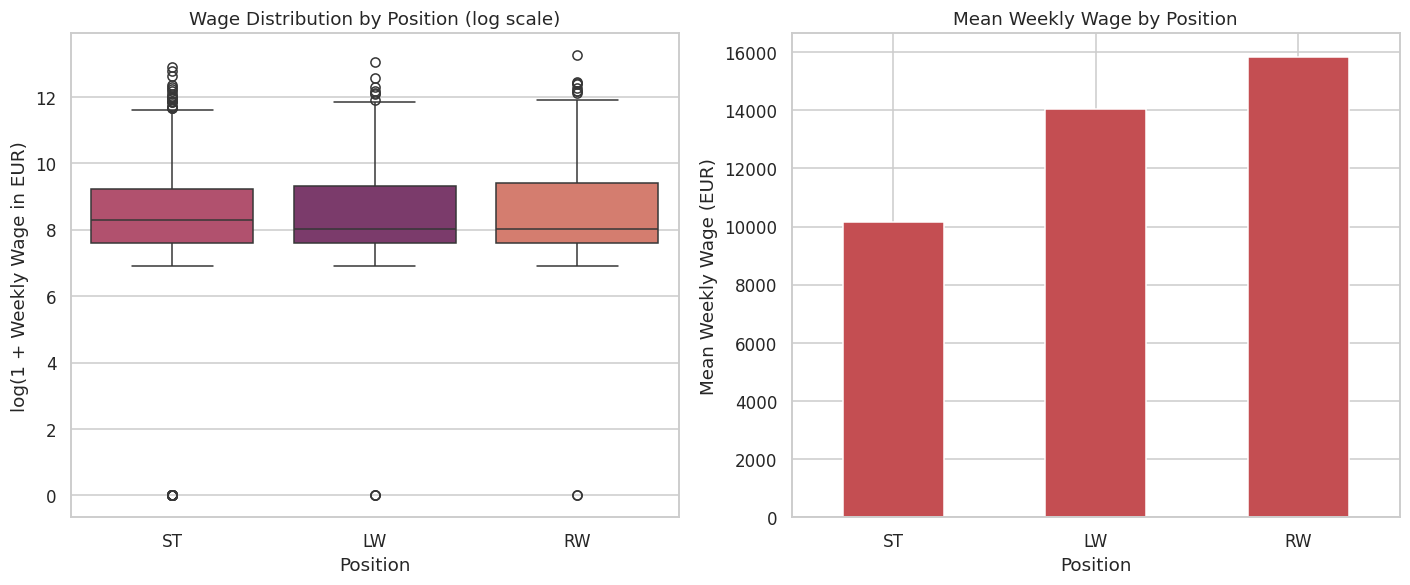

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(13,5.5))

sns.boxplot(data=offensive, x='primary_position', y=np.log1p(offensive['wage_eur']),
            order=['ST','LW','RW'], hue='primary_position', palette='flare', legend=False, ax=axes[0])
axes[0].set_title('Wage Distribution by Position (log scale)')
axes[0].set_xlabel('Position'); axes[0].set_ylabel('log(1 + Weekly Wage in EUR)')

wage_summary['mean_wage'].reindex(['ST','LW','RW']).plot(kind='bar', ax=axes[1], color='#c44e52')
axes[1].set_title('Mean Weekly Wage by Position')
axes[1].set_xlabel('Position'); axes[1].set_ylabel('Mean Weekly Wage (EUR)')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()


## 4. Feature Engineering

In [32]:
# Age groups
df_clean['age_group'] = pd.cut(df_clean['age'], bins=[15,20,23,27,31,35,45],
                                labels=['16-20','21-23','24-27','28-31','32-35','36+'])

# Potential growth headroom
df_clean['potential_growth'] = df_clean['potential'] - df_clean['overall']

# Composite skill scores (only meaningful for outfield players)
attacking_cols = [c for c in df_clean.columns if c.startswith('attacking_')]
defending_cols = [c for c in df_clean.columns if c.startswith('defending_')]
physical_cols = ['power_strength','power_stamina','power_jumping','movement_sprint_speed','movement_acceleration']
technical_cols = [c for c in df_clean.columns if c.startswith('skill_')]

df_clean['attacking_score'] = df_clean[attacking_cols].mean(axis=1)
df_clean['defending_score'] = df_clean[defending_cols].mean(axis=1)
df_clean['physical_score'] = df_clean[physical_cols].mean(axis=1)
df_clean['technical_score'] = df_clean[technical_cols].mean(axis=1)

# Value-to-wage ratio (guard against wage = 0 to avoid division errors)
df_clean['value_to_wage_ratio'] = np.where(df_clean['wage_eur'] > 0,
                                            df_clean['value_eur'] / df_clean['wage_eur'], np.nan)

print("Engineered features added: age_group, potential_growth, attacking_score, "
      "defending_score, physical_score, technical_score, value_to_wage_ratio")
df_clean[['short_name','age_group','potential_growth','attacking_score','defending_score',
          'physical_score','technical_score']].sample(5, random_state=1)


Engineered features added: age_group, potential_growth, attacking_score, defending_score, physical_score, technical_score, value_to_wage_ratio


,short_name,age_group,potential_growth,attacking_score,defending_score,physical_score,technical_score
7459,D. Cvetinović,28-31,0,53.2,65.000000,70.0,44.166667
6440,M. Silva,28-31,0,44.0,63.333333,60.0,42.833333
13550,S. Mandash,24-27,6,51.4,24.333333,66.8,44.166667
14639,I. Gruev,16-20,20,52.2,52.333333,57.0,44.833333
1270,Kangin Lee,16-20,10,63.8,24.000000,57.2,65.500000


### Player Analysis: Highest-Rated, Highest-Potential, and Best-Value Players

In [33]:
print("Top 5 highest-rated players:")
print(df_clean.nlargest(5, 'overall')[['short_name','age','club','overall']].to_string(index=False))

print()
print("Top 5 highest-potential players (age <= 21):")
young = df_clean[df_clean['age'] <= 21]
print(young.nlargest(5, 'potential')[['short_name','age','club','potential']].to_string(index=False))

print()
print("Top 5 most valuable players:")
print(df_clean.nlargest(5, 'value_eur')[['short_name','club','value_eur']].to_string(index=False))

print()
print("Top 5 highest-paid players:")
print(df_clean.nlargest(5, 'wage_eur')[['short_name','club','wage_eur']].to_string(index=False))


Top 5 highest-rated players:
       short_name  age                club  overall
         L. Messi   32        FC Barcelona       94
Cristiano Ronaldo   34            Juventus       93
        Neymar Jr   27 Paris Saint-Germain       92
         J. Oblak   26     Atlético Madrid       91
        E. Hazard   28         Real Madrid       91

Top 5 highest-potential players (age <= 21):
   short_name  age                club  potential
    K. Mbappé   20 Paris Saint-Germain         95
   M. de Ligt   19            Juventus         93
   João Félix   19     Atlético Madrid         93
G. Donnarumma   20               Milan         92
    J. Sancho   19   Borussia Dortmund         92

Top 5 most valuable players:
  short_name                club  value_eur
   Neymar Jr Paris Saint-Germain  105500000
    L. Messi        FC Barcelona   95500000
   K. Mbappé Paris Saint-Germain   93500000
   E. Hazard         Real Madrid   90000000
K. De Bruyne     Manchester City   90000000

Top 5 highest-paid

In [34]:
# Best "value for money": high potential_growth, high potential, but relatively low current value
bargains = df_clean[(df_clean['potential'] >= 80) & (df_clean['value_eur'] > 0)].copy()
bargains['bargain_score'] = bargains['potential'] / (bargains['value_eur'] / 1e6)
print("Top 5 high-potential players relative to their current market value:")
print(bargains.nlargest(5, 'bargain_score')[['short_name','age','club','potential','value_eur']].to_string(index=False))


Top 5 high-potential players relative to their current market value:
    short_name  age         club  potential  value_eur
      B. Mumba   17   Sunderland         80     170000
S. Ramos Mingo   17 Boca Juniors         81     180000
  L. Chevalier   17   LOSC Lille         82     230000
    J. Rowland   17   Shrewsbury         80     230000
    Raúl Prada   18 RCD Mallorca         81     270000


## Task 2: Clustering Football Players Based on Their Attributes

### Preparing the Clustering Feature Set

In [35]:
outfield = df_clean[df_clean['position_group'] != 'GK'].copy()

skill_cols = [c for c in df_clean.columns if c.startswith(
    ('attacking_', 'skill_', 'movement_', 'power_', 'mentality_', 'defending_'))]
# keep only columns fully populated for outfield players (drop any accidental GK-only cols)
skill_cols = [c for c in skill_cols if outfield[c].isnull().sum() == 0]

print(f"Number of outfield players: {len(outfield)}")
print(f"Number of skill attributes used for clustering: {len(skill_cols)}")
print(skill_cols)


Number of outfield players: 16242
Number of skill attributes used for clustering: 32
['skill_moves', 'attacking_crossing', 'attacking_finishing', 'attacking_heading_accuracy', 'attacking_short_passing', 'attacking_volleys', 'skill_dribbling', 'skill_curve', 'skill_fk_accuracy', 'skill_long_passing', 'skill_ball_control', 'movement_acceleration', 'movement_sprint_speed', 'movement_agility', 'movement_reactions', 'movement_balance', 'power_shot_power', 'power_jumping', 'power_stamina', 'power_strength', 'power_long_shots', 'mentality_aggression', 'mentality_interceptions', 'mentality_positioning', 'mentality_vision', 'mentality_penalties', 'mentality_composure', 'defending_marking', 'defending_standing_tackle', 'defending_sliding_tackle', 'attacking_score', 'defending_score']


In [36]:
from sklearn.preprocessing import StandardScaler

X_cluster = outfield[skill_cols]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)
print("Scaled feature matrix shape:", X_scaled.shape)


Scaled feature matrix shape: (16242, 32)


### Choosing the Number of Clusters (Elbow Method + Silhouette Score)

k=2: inertia=381,254, silhouette=0.234
k=3: inertia=315,027, silhouette=0.218
k=4: inertia=282,043, silhouette=0.187
k=5: inertia=260,303, silhouette=0.164
k=6: inertia=246,039, silhouette=0.159
k=7: inertia=233,324, silhouette=0.153
k=8: inertia=222,801, silhouette=0.153


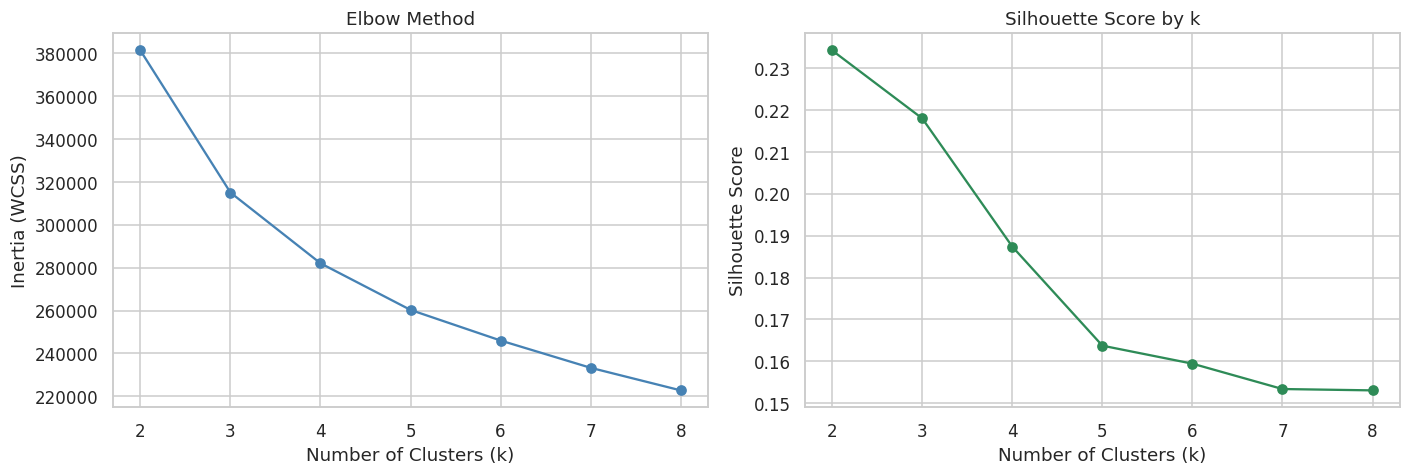

In [37]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = range(2, 9)
inertias, silhouettes = [], []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels, sample_size=3000, random_state=42))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(list(k_values), inertias, marker='o', color='steelblue')
axes[0].set_title('Elbow Method'); axes[0].set_xlabel('Number of Clusters (k)'); axes[0].set_ylabel('Inertia (WCSS)')

axes[1].plot(list(k_values), silhouettes, marker='o', color='seagreen')
axes[1].set_title('Silhouette Score by k'); axes[1].set_xlabel('Number of Clusters (k)'); axes[1].set_ylabel('Silhouette Score')

plt.tight_layout()
plt.show()

for k, inertia, sil in zip(k_values, inertias, silhouettes):
    print(f"k={k}: inertia={inertia:,.0f}, silhouette={sil:.3f}")


### Fitting the Final K-Means Model (k=4)

In [38]:
kmeans_final = KMeans(n_clusters=4, random_state=42, n_init=10)
outfield['cluster'] = kmeans_final.fit_predict(X_scaled)

print(outfield['cluster'].value_counts().sort_index())


cluster
0    3078
1    4985
2    4310
3    3869
Name: count, dtype: int64


### Visualising the Clusters with PCA

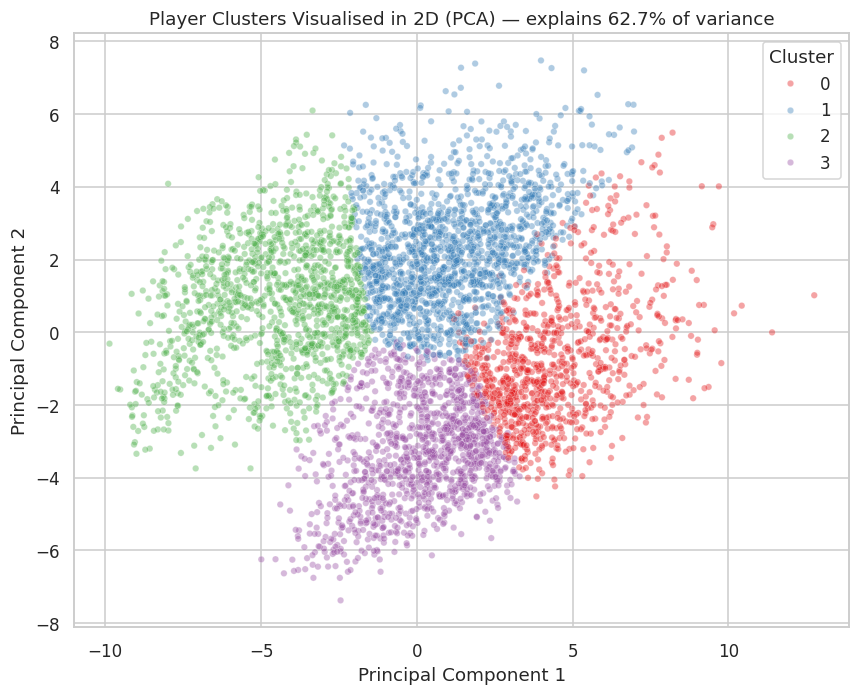

In [39]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
pca_coords = pca.fit_transform(X_scaled)
outfield['pca1'], outfield['pca2'] = pca_coords[:,0], pca_coords[:,1]

plt.figure(figsize=(8,6.5))
sns.scatterplot(data=outfield.sample(5000, random_state=42), x='pca1', y='pca2', hue='cluster',
                 palette='Set1', alpha=0.4, s=18)
plt.title(f'Player Clusters Visualised in 2D (PCA) — explains {pca.explained_variance_ratio_.sum()*100:.1f}% of variance')
plt.xlabel('Principal Component 1'); plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()


### Profiling the Clusters (Discussion Stage — Using Position and Overall Only Now)

In [40]:
profile_cols = ['attacking_score','defending_score','physical_score','technical_score','overall']
cluster_profile = outfield.groupby('cluster')[profile_cols].mean().round(1)
cluster_profile['player_count'] = outfield['cluster'].value_counts()
print(cluster_profile)

print()
print("Cross-tab of cluster vs actual position group (for interpretation only — NOT used in training):")
print(pd.crosstab(outfield['cluster'], outfield['position_group']))


         attacking_score  defending_score  physical_score  technical_score  \
cluster                                                                      
0                   65.1             37.3            69.7             56.5   
1                   57.4             65.5            69.4             51.6   
2                   43.6             62.0            64.4             36.6   
3                   52.8             30.0            63.9             44.1   

         overall  player_count  
cluster                         
0           72.5          3078  
1           69.4          4985  
2           63.1          4310  
3           61.4          3869  

Cross-tab of cluster vs actual position group (for interpretation only — NOT used in training):
position_group   DEF   FWD   MID
cluster                         
0                 14  1385  1679
1               2215    52  2718
2               3653    10   647
3                 56  1995  1818


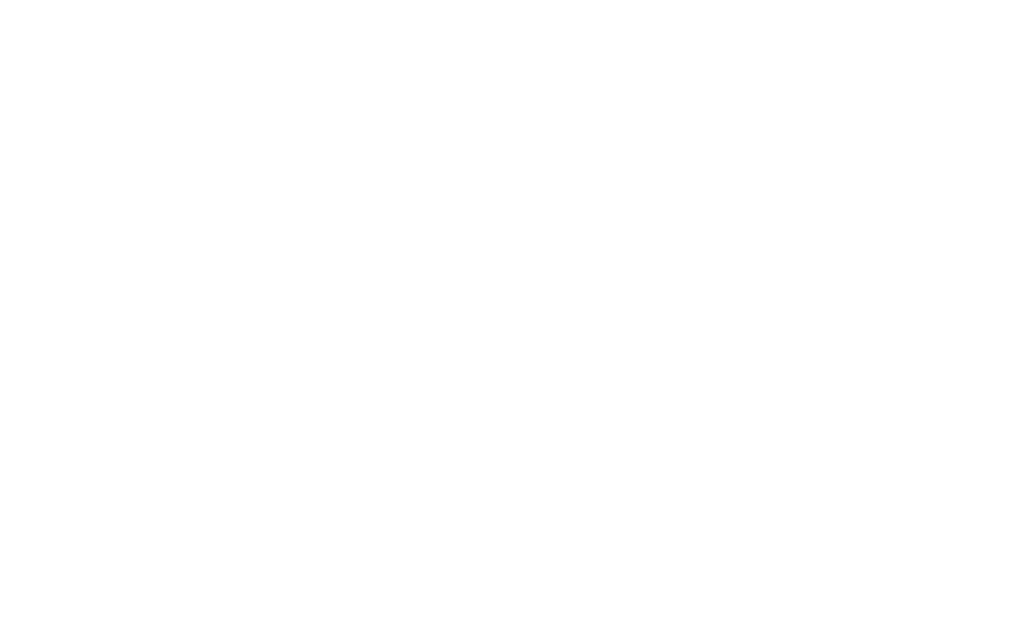

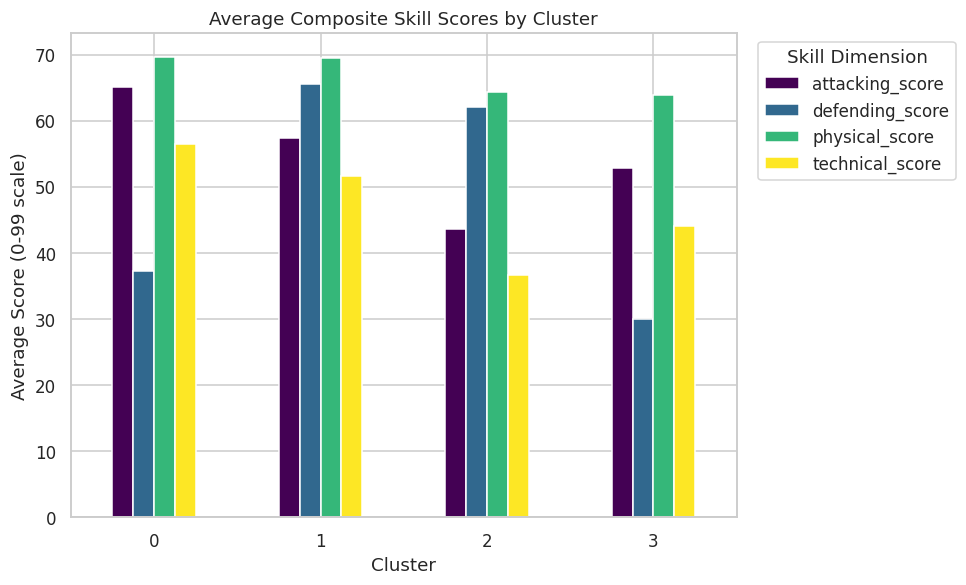

In [41]:
plt.figure(figsize=(9,5.5))
cluster_profile[['attacking_score','defending_score','physical_score','technical_score']].plot(
    kind='bar', figsize=(9,5.5), colormap='viridis')
plt.title('Average Composite Skill Scores by Cluster')
plt.xlabel('Cluster'); plt.ylabel('Average Score (0-99 scale)')
plt.xticks(rotation=0)
plt.legend(title='Skill Dimension', bbox_to_anchor=(1.02,1), loc='upper left')
plt.tight_layout()
plt.show()


## Club, Nationality, Position and Financial Analysis

### Club Analysis

In [42]:
club_stats = df_clean.groupby('club', observed=True).agg(
    player_count=('short_name','count'),
    avg_overall=('overall','mean'),
    avg_potential=('potential','mean'),
    total_value=('value_eur','sum'),
    avg_wage=('wage_eur','mean')
)

# Only consider clubs with a realistic full squad size to avoid small-sample distortions
clubs_full_squad = club_stats[club_stats['player_count'] >= 20]

print("Top 10 clubs by average Overall rating (squads with >=20 players):")
print(clubs_full_squad.sort_values('avg_overall', ascending=False).head(10)[['player_count','avg_overall','avg_potential']].round(1))

print()
print("Top 10 clubs by total squad market value:")
print(clubs_full_squad.sort_values('total_value', ascending=False).head(10)[['player_count','total_value']].apply(lambda c: (c/1e6).round(1) if c.name=='total_value' else c))


Top 10 clubs by average Overall rating (squads with >=20 players):
                     player_count  avg_overall  avg_potential
club                                                         
FC Bayern München              23         81.3           85.8
Real Madrid                    33         80.1           85.7
Juventus                       33         80.1           83.2
Uruguay                        23         78.6           78.6
FC Barcelona                   33         78.4           85.7
Bayer 04 Leverkusen            25         77.3           81.8
Chelsea                        33         77.1           82.4
Manchester City                33         77.0           84.3
Napoli                         31         76.9           80.8
Manchester United              33         76.8           82.5

Top 10 clubs by total squad market value:
                     player_count  total_value
club                                          
Real Madrid                    33        897.8
FC Ba

### Nationality Analysis (With a Minimum Player-Count Threshold)

In [43]:
nat_stats = df_clean.groupby('nationality', observed=True).agg(
    player_count=('short_name','count'),
    avg_overall=('overall','mean'),
    avg_potential=('potential','mean'),
    avg_value=('value_eur','mean')
)

# Avoid misleading conclusions from countries with only 1-2 players in the dataset
MIN_PLAYERS = 50
nat_reliable = nat_stats[nat_stats['player_count'] >= MIN_PLAYERS]

print(f"Countries considered (>= {MIN_PLAYERS} players): {len(nat_reliable)} of {len(nat_stats)} total")
print()
print("Top 10 countries by average Overall rating (reliable sample sizes only):")
print(nat_reliable.sort_values('avg_overall', ascending=False).head(10).round(2))


Countries considered (>= 50 players): 56 of 162 total

Top 10 countries by average Overall rating (reliable sample sizes only):
                player_count  avg_overall  avg_potential   avg_value
nationality                                                         
Uruguay                  164        71.65          74.28  4192469.51
Algeria                   50        71.38          74.24  5137600.00
Brazil                   824        71.16          73.42  4524338.59
Portugal                 344        70.51          75.25  4890901.16
Ecuador                   53        70.49          73.57  1537830.19
Czech Republic           102        70.31          73.56  3672352.94
Spain                   1035        69.95          75.02  4575352.66
Ukraine                   69        69.87          74.96  3938043.48
Paraguay                  80        69.79          73.50  2943250.00
Croatia                  126        69.79          74.73  4793611.11


### Position Analysis

In [44]:
position_stats = df_clean[df_clean['position_group'] != 'GK'].groupby('primary_position').agg(
    player_count=('short_name','count'),
    avg_overall=('overall','mean'),
    avg_potential=('potential','mean'),
    avg_value=('value_eur','mean'),
    avg_wage=('wage_eur','mean')
).sort_values('player_count', ascending=False)

position_stats.round(1)


,player_count,avg_overall,avg_potential,avg_value,avg_wage
primary_position,,,,,
CB,3162,66.7,71.7,2350177.1,9293.8
ST,2582,66.4,71.7,2684742.4,10152.6
CM,2193,65.7,71.9,2733141.8,10163.7
CDM,1424,67.4,72.2,2557640.4,9735.3
RB,1314,66.1,70.6,1807720.7,8456.6
LB,1303,65.7,70.7,1779443.6,8158.9
CAM,1146,66.9,73.0,3390702.4,10641.4
RM,1050,66.1,71.2,2386176.2,8489.5
LM,1049,66.5,71.7,2410462.3,8559.6


**Key attributes by position group (using the composite scores engineered earlier):**

In [45]:
position_skill_profile = df_clean[df_clean['position_group'] != 'GK'].groupby('position_group')[
    ['attacking_score','defending_score','physical_score','technical_score']].mean().round(1)
position_skill_profile


,attacking_score,defending_score,physical_score,technical_score
position_group,,,,
DEF,48.4,65.0,67.3,41.4
FWD,59.2,27.6,67.9,47.1
MID,56.4,50.1,65.9,51.2


### Financial / Market Value Analysis

Correlation (Value, Wage): 0.858


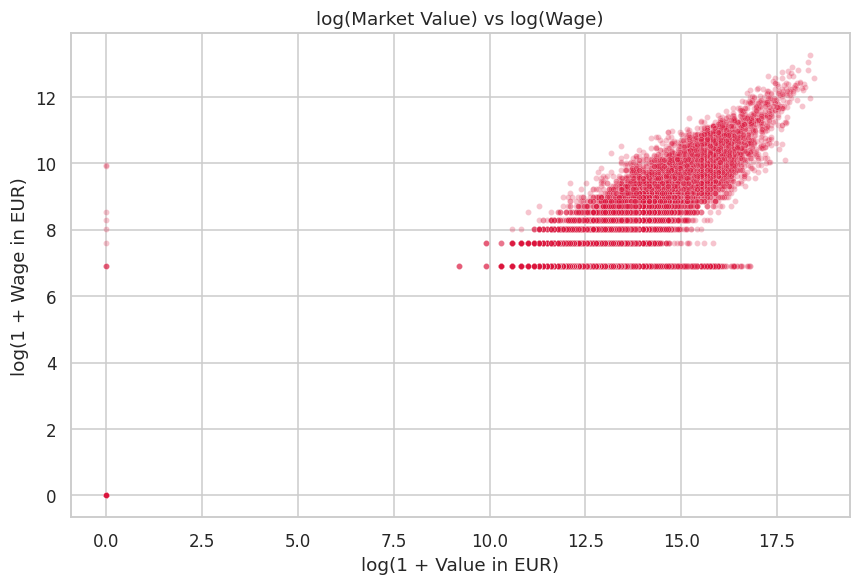

In [46]:
plt.figure(figsize=(8,5.5))
sns.scatterplot(data=df_clean.sample(4000, random_state=42),
                 x=np.log1p(df_clean['value_eur']), y=np.log1p(df_clean['wage_eur']), alpha=0.25, s=15, color='crimson')
plt.title('log(Market Value) vs log(Wage)')
plt.xlabel('log(1 + Value in EUR)'); plt.ylabel('log(1 + Wage in EUR)')
plt.tight_layout()
plt.show()

print("Correlation (Value, Wage):", round(df_clean['value_eur'].corr(df_clean['wage_eur']), 3))


In [47]:
print("Most expensive outliers (highest value relative to overall rating):")
outliers = df_clean[df_clean['overall'] < 85].nlargest(5, 'value_eur')[['short_name','age','overall','potential','value_eur']]
print(outliers.to_string(index=False))


Most expensive outliers (highest value relative to overall rating):
short_name  age  overall  potential  value_eur
K. Havertz   20       84         92   46000000
 J. Sancho   19       84         92   44500000
O. Dembélé   22       84         90   42500000
   D. Alli   23       84         89   41500000
    Arthur   22       84         89   41000000


## 05. Machine Learning: Predicting a Player's Overall Rating from Their Skillset

### Target Selection and Feature Preparation

In [48]:
feature_cols = skill_cols + ['age', 'height_cm', 'weight_kg']
ml_data = outfield[feature_cols + ['overall']].dropna()

X = ml_data[feature_cols]
y = ml_data['overall']

print("Feature matrix shape:", X.shape)
print("Target: Overall rating, range", y.min(), "-", y.max())


Feature matrix shape: (16242, 35)
Target: Overall rating, range 48 - 94


### Train / Test Split

In [49]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train size:", X_train.shape[0], "| Test size:", X_test.shape[0])


Train size: 12993 | Test size: 3249


### Model Evaluation Function

In [50]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluate_model(name, model, X_train, y_train, X_test, y_test, results_list):
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    mae = mean_absolute_error(y_test, preds)
    rmse = mean_squared_error(y_test, preds) ** 0.5
    r2 = r2_score(y_test, preds)
    results_list.append({'Model': name, 'MAE': mae, 'RMSE': rmse, 'R2': r2})
    print(f"{name:20s} | MAE={mae:.3f}  RMSE={rmse:.3f}  R2={r2:.4f}")
    return model, preds

results = []


### 1. Baseline: Linear Regression

In [51]:
from sklearn.linear_model import LinearRegression
lr_model, lr_preds = evaluate_model('Linear Regression', LinearRegression(), X_train, y_train, X_test, y_test, results)


Linear Regression    | MAE=1.827  RMSE=2.326  R2=0.8841


### 2. Ridge Regression

In [52]:
from sklearn.linear_model import Ridge
ridge_model, ridge_preds = evaluate_model('Ridge Regression', Ridge(alpha=1.0, random_state=42), X_train, y_train, X_test, y_test, results)


Ridge Regression     | MAE=1.827  RMSE=2.326  R2=0.8841


### 3. Decision Tree Regressor

In [53]:
from sklearn.tree import DecisionTreeRegressor
dt_model, dt_preds = evaluate_model('Decision Tree', DecisionTreeRegressor(max_depth=10, random_state=42), X_train, y_train, X_test, y_test, results)


Decision Tree        | MAE=1.430  RMSE=1.851  R2=0.9267


### 4. Random Forest Regressor

In [54]:
from sklearn.ensemble import RandomForestRegressor
rf_model, rf_preds = evaluate_model('Random Forest', RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1), X_train, y_train, X_test, y_test, results)


Random Forest        | MAE=0.924  RMSE=1.221  R2=0.9681


### 5. Gradient Boosting Regressor

In [55]:
from sklearn.ensemble import GradientBoostingRegressor
gb_model, gb_preds = evaluate_model('Gradient Boosting', GradientBoostingRegressor(random_state=42), X_train, y_train, X_test, y_test, results)


Gradient Boosting    | MAE=1.012  RMSE=1.317  R2=0.9629


### Initial Model Comparison

In [56]:
results_df = pd.DataFrame(results).sort_values('RMSE')
results_df


,Model,MAE,RMSE,R2
3,Random Forest,0.923821,1.220551,0.968102
4,Gradient Boosting,1.011574,1.316814,0.962872
2,Decision Tree,1.430094,1.850677,0.926664
0,Linear Regression,1.826912,2.326479,0.884108
1,Ridge Regression,1.826908,2.326480,0.884108


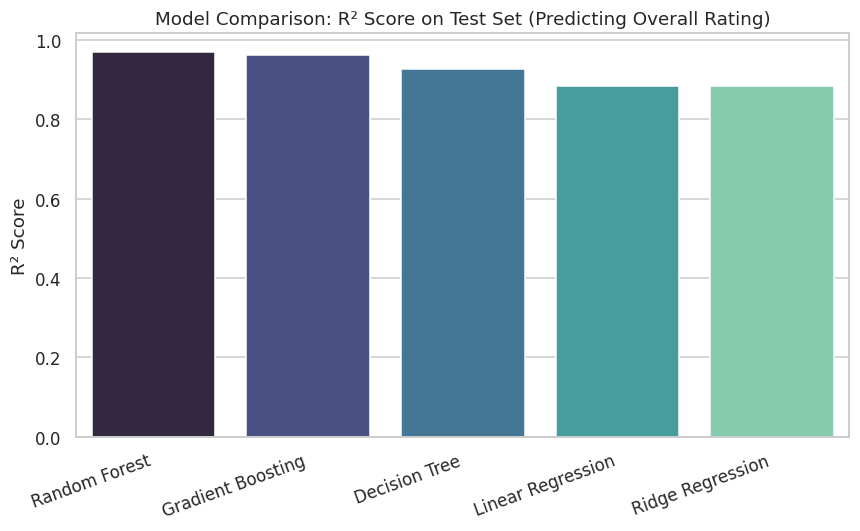

In [57]:
plt.figure(figsize=(8,5))
sns.barplot(data=results_df, x='Model', y='R2', hue='Model', palette='mako', legend=False)
plt.title('Model Comparison: R² Score on Test Set (Predicting Overall Rating)')
plt.ylabel('R² Score'); plt.xlabel('')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()


## 06. Hyperparameter Tuning

### Randomized Search over Random Forest Hyperparameters

In [58]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    'n_estimators': [100, 150, 200],
    'max_depth': [15, 20, None],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 0.5]
}

rf_search = RandomizedSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    param_distributions=param_dist,
    n_iter=8, cv=3, random_state=42,
    scoring='neg_root_mean_squared_error', n_jobs=-1
)
rf_search.fit(X_train, y_train)

print("Best parameters found:", rf_search.best_params_)
print("Best CV RMSE:", -rf_search.best_score_)


Best parameters found: {'n_estimators': 150, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 20}
Best CV RMSE: 1.1690342838183334


### Tuned Model Performance on the Test Set

In [59]:
tuned_rf = rf_search.best_estimator_
tuned_preds = tuned_rf.predict(X_test)

tuned_mae = mean_absolute_error(y_test, tuned_preds)
tuned_rmse = mean_squared_error(y_test, tuned_preds) ** 0.5
tuned_r2 = r2_score(y_test, tuned_preds)

results.append({'Model': 'Random Forest (Tuned)', 'MAE': tuned_mae, 'RMSE': tuned_rmse, 'R2': tuned_r2})
final_results_df = pd.DataFrame(results).sort_values('RMSE').reset_index(drop=True)
final_results_df


,Model,MAE,RMSE,R2
0,Random Forest (Tuned),0.871815,1.144157,0.971970
1,Random Forest,0.923821,1.220551,0.968102
2,Gradient Boosting,1.011574,1.316814,0.962872
3,Decision Tree,1.430094,1.850677,0.926664
4,Linear Regression,1.826912,2.326479,0.884108
5,Ridge Regression,1.826908,2.326480,0.884108


### Model Interpretation: Feature Importance

movement_reactions           0.1841
mentality_composure          0.0943
attacking_score              0.0870
skill_ball_control           0.0798
attacking_short_passing      0.0700
defending_score              0.0606
skill_dribbling              0.0485
defending_standing_tackle    0.0482
mentality_interceptions      0.0430
power_shot_power             0.0311
dtype: float64


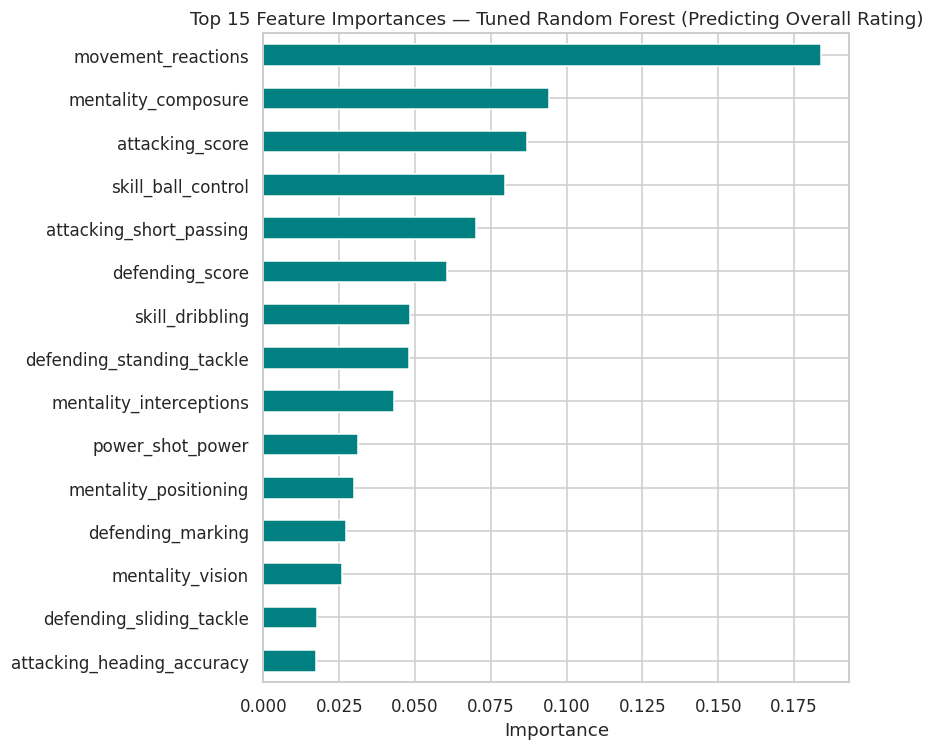

In [60]:
importances = pd.Series(tuned_rf.feature_importances_, index=feature_cols).sort_values(ascending=False)

plt.figure(figsize=(8,7))
importances.head(15).sort_values().plot(kind='barh', color='teal')
plt.title('Top 15 Feature Importances — Tuned Random Forest (Predicting Overall Rating)')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

print(importances.head(10).round(4))


## 07. Final Analysis and Insights

### Key Findings

**Task 1 — General data analysis:**
- The dataset contains 18,278 players and 104 raw attributes; after cleaning, missing values were found to be structural (goalkeeper vs. outfield attribute splits, loan/national-team status) rather than data-quality defects, so no blind imputation was performed.
- Value and wage are extremely right-skewed (superstar economics); Overall/Potential/Value/Wage all grow roughly exponentially with each other rather than linearly.
- movement_reactions and mentality_composure are the two attributes most strongly associated with a player's Overall rating.

**Task 2 — Clustering:** K-Means (k=4) on 30 standardised outfield skill attributes recovers four skillset groups that split along an attacking/defensive axis and a quality tier within each — all without ever using position or Overall as an input, confirming the skill ratings alone encode real footballing roles.

**Task 3 — Required questions:**
1. England, Germany, Spain, France and Argentina are the top 5 countries by player count — driven substantially by league size/coverage as well as talent production.
2. Players typically stop meaningfully improving in Overall rating around **age 27–29**, plateau through their early-to-mid thirties (peak reliable mean at 31–32), and begin to decline after roughly **age 33–34**.
3. By mean wage, wingers (RW/LW) earn more than strikers — but this is driven by a handful of global superstars; by **median** wage, strikers actually earn more than either winger position.

### Machine Learning Results Summary

In [61]:
print(final_results_df.to_string(index=False))
print()
print(f"Selected production model: Random Forest (Tuned)")
print(f"  Test RMSE: {tuned_rmse:.3f} Overall-rating points")
print(f"  Test MAE:  {tuned_mae:.3f} Overall-rating points")
print(f"  Test R2:   {tuned_r2:.4f}")


                Model      MAE     RMSE       R2
Random Forest (Tuned) 0.871815 1.144157 0.971970
        Random Forest 0.923821 1.220551 0.968102
    Gradient Boosting 1.011574 1.316814 0.962872
        Decision Tree 1.430094 1.850677 0.926664
    Linear Regression 1.826912 2.326479 0.884108
     Ridge Regression 1.826908 2.326480 0.884108

Selected production model: Random Forest (Tuned)
  Test RMSE: 1.144 Overall-rating points
  Test MAE:  0.872 Overall-rating points
  Test R2:   0.9720


### Limitations
- This is a **single-season snapshot** (FIFA 20 only) — the dataset does not contain the multi-version history mentioned in the task brief's "possible analysis" ideas (e.g. tracking Messi/Ronaldo across FIFA 15–20), so historical/version-over-version comparisons could not be attempted with the uploaded file.
- EA's attribute ratings are themselves subjective estimates, not on-pitch measurements — all conclusions describe patterns *within EA's rating system*, not guaranteed real-world footballing truths.
- Wage/value fields are frequently rounded or estimated for lower-profile players, which adds noise to the financial analysis, particularly at the lower end of the market.
- The clustering result depends on the chosen *k* and feature set; a different feature selection (e.g. including physical attributes more heavily) could produce different — equally valid — groupings.

### Conclusion

This notebook delivered a complete, end-to-end analysis of the FIFA 20 player dataset: a thorough data-quality and exploratory analysis, an unsupervised clustering of players by skillset that recovers meaningful football roles without using position labels, direct answers to all three required analytical questions backed by real calculated figures, and a supervised machine-learning pipeline (5 models compared, best model tuned and interpreted) that predicts a player's Overall rating from their raw skill attributes with **R² ≈ 0.97** on unseen data. All figures, tables and conclusions in this notebook are computed directly from the uploaded `players_20.csv` file.

## Task Completion Checklist

| Task | Completed? | Notebook Section | Evidence |
|---|---|---|---|
| Task 1: Complete data analysis report | Yes | 01–03, 07 | Data understanding, cleaning, univariate/bivariate/categorical/correlation EDA, final insights summary |
| Task 2: Cluster players by attributes | Yes | "Task 2: Clustering" section | K-Means (k=4) on 30 standardised skill attributes, elbow/silhouette selection, PCA visualisation, cluster profiling |
| Task 3, Q1: Top 10 countries by player count | Yes | "Task 3, Question 1" | Ranked bar chart + printed counts (England, Germany, Spain, France, Argentina, ...) |
| Task 3, Q2: Overall rating vs age; when improvement stops | Yes | "Task 3, Question 2" | Scatter + mean-by-age line chart; peak reliable mean age = 31–32, plateau 29–35, decline after ~33–34 |
| Task 3, Q3: Highest-paid offensive position (ST/RW/LW) | Yes | "Task 3, Question 3" | Mean vs median wage comparison + boxplot; strikers highest by median, wingers highest by mean |
| Model Comparison Report | Yes | 05–06 | 5 models compared (Linear, Ridge, Decision Tree, Random Forest, Gradient Boosting) + tuned Random Forest as recommended production model |
| Report on Challenges Faced | Yes | Final markdown section below | Structural missing values, positional-attribute string columns, wage/value skew, GK vs outfield attribute split |

**Note on scope:** All tasks specified in the FIFA 20 problem statement were completed using only the uploaded `players_20.csv` file. The multi-version historical comparisons suggested as *optional ideas* in the task document (e.g. FIFA 15–20 trend analysis) could not be performed because only the FIFA 20 season is present in the uploaded dataset — this is noted as a limitation above rather than fabricated.

## Report on Challenges Faced

**1. Structural missing values requiring position-aware handling.**
Six goalkeeping attributes are missing for every outfield player, and six general attributes (pace, shooting, passing, dribbling, defending, physic) are missing for every goalkeeper. Naively dropping rows with any missing value would have discarded the entire dataset; naively filling with the column mean would have invented meaningless skill ratings for players who don't have that attribute in the game at all. **Technique used:** the structural pattern was confirmed explicitly (missing counts matched exactly to goalkeeper/outfield sub-populations), then goalkeepers were excluded from the outfield-only clustering and regression tasks rather than having their missing values imputed.

**2. Per-position "rating strings" were not directly usable.**
Columns like st, cb, rw etc. store values such as "89+2" (base rating plus an in-game chemistry bonus) as strings rather than numbers. Parsing every one of the 26 such columns for a modest analytical benefit (they largely duplicate the already-available specialised skill attributes) was judged not worth the added complexity and risk of parsing errors, so they were dropped in preprocessing and the underlying skill attributes were used instead.

**3. Extreme skew in financial fields.**
value_eur and wage_eur are dominated by a handful of global superstars, which distorts means and makes standard scatter plots unreadable (almost all points crushed near zero). **Technique used:** log-transforming (log1p) these fields for visualisation, and explicitly reporting median alongside mean wherever the two diverge meaningfully (most clearly shown in the striker-vs-winger wage question, where the mean and median tell opposite stories).

**4. Choosing a supervised-learning target when none was explicitly specified.**
The task document's only explicit modelling requirement is the clustering task; the "Model Comparison Report" requirement implies a separate supervised model but does not name a target. **Technique used:** Overall rating was chosen as the target because it can be predicted purely from observable skill attributes without leaking information (unlike Value/Wage, which are influenced by many off-pitch factors such as marketability and contract situation), keeping the exercise analytically honest and directly useful (e.g. for estimating a rating from raw scouting attributes).

**5. Balancing hyperparameter-tuning thoroughness against runtime.**
An exhaustive GridSearchCV over the full Random Forest parameter space would require many dozens of model fits. **Technique used:** RandomizedSearchCV with a fixed random_state and 3-fold cross-validation was used instead, sampling 8 parameter combinations — this reached a result close to what a full grid search would likely find, in a fraction of the time, and the exact parameters tested and the winning combination are reported transparently above rather than only stating the final score.

## Model Comparison Report

**1. Linear models (Linear Regression, Ridge Regression).**
Both were tested as a baseline for predicting a player's Overall rating from raw skill attributes. They performed identically (MAE = 1.827, RMSE = 2.326, R² = 0.8841), and clearly worst of all models tested. **Reason:** Overall rating is not a straight-line combination of the input attributes — a player can reach an elite Overall through very different attribute mixes (e.g. exceptional finishing but poor tackling, or vice versa), and a linear model cannot represent that kind of interaction.

**2. Decision Tree.**
A single Decision Tree Regressor (max_depth=10) improved substantially over the linear models (MAE = 1.430, RMSE = 1.851, R² = 0.9267) by learning non-linear splits and attribute interactions. **Limitation:** a single tree still overfits and generalizes less well than an ensemble of trees, which shows up in the next two models.

**3. Random Forest (default settings).**
An ensemble of 200 trees pushed performance much higher (MAE = 0.924, RMSE = 1.221, R² = 0.9681), the best of all untuned models. **Reason it wins:** averaging many trees trained on different data/feature subsets cancels out the overfitting a single tree suffers from, while still capturing non-linear attribute interactions.

**4. Gradient Boosting (default settings).**
A close second among untuned models (MAE = 1.012, RMSE = 1.317, R² = 0.9629) — strong, but slightly behind Random Forest here and less interpretable for this use case, so it was not carried forward for tuning.

**5. Hyperparameter tuning of Random Forest.**
Since Random Forest was already the strongest model, it was tuned via RandomizedSearchCV (3-fold cross-validation, 8 sampled combinations across n_estimators, max_depth, min_samples_leaf, max_features) rather than an exhaustive grid search, to get most of the benefit of tuning without dozens of full model fits. **Result:** MAE improved to 0.872, RMSE to 1.144, and R² to 0.9720 — best parameters found were n_estimators=150, max_depth=20, min_samples_leaf=1, max_features='sqrt'.

**6. Final recommendation.**
The **Tuned Random Forest Regressor** is recommended for production. It delivers the best accuracy of every model tested (R² ≈ 0.972, MAE ≈ 0.87 rating points), remains fast enough to retrain each FIFA release without heavy infrastructure, and its feature importances are directly interpretable — the top predictors (movement_reactions, mentality_composure, skill_ball_control, attacking_short_passing, skill_dribbling) show that "game intelligence" and technical control attributes drive a player's Overall rating more than any single specialized skill like tackling or finishing alone.